<a href="https://colab.research.google.com/github/Beatricepapi/ml-campus_data_project-colab/blob/main/Beatrice_Papi_Machine_Learning_with_Python_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Campus Synthetic Dataset**

In [48]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [49]:
import pandas as pd

#**Project Introduction**

##Project Title
Exploring Campus Nature and Human Experience Through Data and Machine Learning

###Research Question
How can data collected during a campus nature walk be used to investigate the relationship between environmental characteristics and human experience?

###Project Aim
The aim of this project is to explore how different environmental characteristics around the ATU Galway campus may relate to people's wellbeing and experiences.

Using Python, I will clean, explore and visualise the campus dataset to identify patterns and possible relationships between environmental factors, such as sound levels, weather, foot traffic and natural features, and human experiences, such as stress, wellbeing and connection with nature.

I will also apply machine-learning techniques to investigate these patterns and evaluate the results.

#**Load the Dataset**

In [50]:
df = pd.read_csv(
    '/content/drive/MyDrive/CampusWalkDataset_TemplateIDs(Sheet1).csv',
    skiprows=4
)


#**Inspect the Dataset structure**

In [51]:
print(df.shape)
print('\nThe first 5 rows of my dataset:')
print(df.head())


(994, 27)

The first 5 rows of my dataset:
  recorder_id       date                        location        weather  \
0     R26_001  9/22/2026                L01 MainEntrance  Partly cloudy   
1     R26_001  9/22/2026                L02 LibraryGreen          Sunny   
2     R26_001  9/22/2026   L06 HedgingBehindSportsCentre  Partly cloudy   
3     R26_001  9/22/2026  L08 AccessRoadNearSportsCentre  Partly cloudy   
4     R26_001  9/22/2026   L06 HedgingBehindSportsCentre          Sunny   

  temperature_c sound level foot_traffic primary_sound_type_urban  \
0            16       Quiet          Low             Human voices   
1            16    Moderate          Low                  Traffic   
2            16       Quiet          Low             Construction   
3            16    Moderate          Low             Human voices   
4            16    Moderate          Low                  Traffic   

  other_sound_type_urban primary_sound_type_nature  ...    wellbeing_rating  \
0           

#**Check Dataset information**

In [52]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 994 entries, 0 to 993
Data columns (total 27 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   recorder_id                            199 non-null    object 
 1   date                                   135 non-null    object 
 2   location                               135 non-null    object 
 3   weather                                135 non-null    object 
 4   temperature_c                          135 non-null    object 
 5   sound level                            135 non-null    object 
 6   foot_traffic                           135 non-null    object 
 7   primary_sound_type_urban               135 non-null    object 
 8   other_sound_type_urban                 132 non-null    object 
 9   primary_sound_type_nature              135 non-null    object 
 10  other_sound_type_nature                133 non-null    object 
 11  insect

#**Check for missing values**

In [53]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
recorder_id                              795
date                                     859
location                                 859
weather                                  859
temperature_c                            859
sound level                              859
foot_traffic                             859
primary_sound_type_urban                 859
other_sound_type_urban                   862
primary_sound_type_nature                859
other_sound_type_nature                  861
insects_count                            859
birds_count                              859
trees_presence                           864
native_or_wild_plant_presence            871
ornnamental_or_planted_plant_presence    897
moss_or_lichen_presence                  895
wellbeing_rating                         859
ease_rating                              859
stress_rating                            859
nature_connection_experience_rating      859
most_notable_nature_element           

#**Check for duplicate rows**

In [54]:
print("\nDuplicate rows:")
print(df.duplicated().sum())



Duplicate rows:
844


##Create a copy o the original Dataset

In [55]:
df_clean = df.copy()

##Remove rows without a reorded location

In [56]:
df_clean = df_clean.dropna(subset=['location'])

##Remove completely empty columns

In [57]:
df_clean = df_clean.dropna(axis=1, how='all')

##Display the cleaned dataset dimensions

In [58]:
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)

Original dataset: (994, 27)
Cleaned dataset: (135, 23)


#**Display the first five cleaned rows**

In [59]:
display(df_clean.head())


,recorder_id,date,location,weather,temperature_c,sound level,foot_traffic,primary_sound_type_urban,other_sound_type_urban,primary_sound_type_nature,...,trees_presence,native_or_wild_plant_presence,ornnamental_or_planted_plant_presence,moss_or_lichen_presence,wellbeing_rating,ease_rating,stress_rating,nature_connection_experience_rating,most_notable_nature_element,other_notes
0,R26_001,9/22/2026,L01 MainEntrance,Partly cloudy,16,Quiet,Low,Human voices,Traffic,Wind,...,Many,Some,Some,Some,Positive wellbeing,Neutral,Stressful,Less connected,Plants and trees,NaN
1,R26_001,9/22/2026,L02 LibraryGreen,Sunny,16,Moderate,Low,Traffic,Human voices,Wind,...,Many,NaN,Some,NaN,Positive wellbeing,Neutral,Neutral,A little more connected,Sunrays on grass,NaN
2,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Partly cloudy,16,Quiet,Low,Construction,Traffic,Wind,...,Many,NaN,Many,Some,Positive wellbeing,Easy,Mostly calm,No change,Very quiet,NaN
3,R26_001,9/22/2026,L08 AccessRoadNearSportsCentre,Partly cloudy,16,Moderate,Low,Human voices,Human voices,Wind,...,One or two,Some,NaN,Some,Positive wellbeing,Neutral,Neutral,Much more connected,Harsh wind,NaN
4,R26_001,9/22/2026,L06 HedgingBehindSportsCentre,Sunny,16,Moderate,Low,Traffic,Other,Wind,...,One or two,NaN,Some,NaN,Positive wellbeing,Easy,Mostly calm,Less connected,Crowded area,NaN


#**Weekly Decision Log**

##Decision 1 – Initial Dataset Cleaning

| Question | My Decision |
|---|---|
| **Issue / Challenge** | The original dataset contained 994 rows and 27 columns, but many rows had missing values. |
| **Decision Taken** | I created a copy of the original dataset, removed rows without a recorded location and removed completely empty columns. |
| **Justification** | I wanted to keep the original data unchanged while preparing the observations for analysis. |
| **Evidence** | The original dataset contained 994 rows and 27 columns. After cleaning, it contained 135 rows and 23 columns. |
| **AI Use** | I used ChatGPT to help me understand how to inspect and clean the dataset using Pandas. |
| **Reflection / Learning** | I learned how to identify missing data, create a copy of a DataFrame, and remove unnecessary rows and columns. |

#**Check Remaining Missing Values and Duplicates**


##Check missing values in the cleaned dataset

In [60]:
print("Missing values after cleaning:")
print(df_clean.isnull().sum())

Missing values after cleaning:
recorder_id                               0
date                                      0
location                                  0
weather                                   0
temperature_c                             0
sound level                               0
foot_traffic                              0
primary_sound_type_urban                  0
other_sound_type_urban                    3
primary_sound_type_nature                 0
other_sound_type_nature                   2
insects_count                             0
birds_count                               0
trees_presence                            5
native_or_wild_plant_presence            12
ornnamental_or_planted_plant_presence    38
moss_or_lichen_presence                  36
wellbeing_rating                          0
ease_rating                               0
stress_rating                             0
nature_connection_experience_rating       0
most_notable_nature_element              15
o

##Check duplicate rows in the cleaned dataset

In [61]:
print("\nDuplicate rows after cleaning:")
print(df_clean.duplicated().sum())



Duplicate rows after cleaning:
0


#**Investigate Missing Values in Nature-Related Columns**

##Inspect the values in nature-related columns

In [62]:
nature_columns = [
    'trees_presence',
    'native_or_wild_plant_presence',
    'ornnamental_or_planted_plant_presence',
    'moss_or_lichen_presence'
]

for col in nature_columns:
    print("\n", col)
    print(df_clean[col].value_counts(dropna=False))



 trees_presence
trees_presence
Many          101
One or two     29
NaN             5
Name: count, dtype: int64

 native_or_wild_plant_presence
native_or_wild_plant_presence
Some     78
Many     45
NaN      12
Name: count, dtype: int64

 ornnamental_or_planted_plant_presence
ornnamental_or_planted_plant_presence
Some     60
NaN      38
Many     37
Name: count, dtype: int64

 moss_or_lichen_presence
moss_or_lichen_presence
Some     63
NaN      36
Many     34
Some      2
Name: count, dtype: int64


#**Standardise Text Values**

##Remove extra spaces from text values

In [63]:
for col in df_clean.select_dtypes(include='object').columns:
    df_clean[col] = df_clean[col].str.strip()

##Check moss or lichen values again

In [64]:
print(df_clean['moss_or_lichen_presence'].value_counts(dropna=False))


moss_or_lichen_presence
Some    65
NaN     36
Many    34
Name: count, dtype: int64


### Weekly Decision Log – Decision 2: Handling Missing Values and Inconsistent Text

| Question | My Decision |
|---|---|
| **Issue / Challenge** | After the initial cleaning, I found remaining missing values in some nature-related columns and inconsistent text values in the moss or lichen column. |
| **Decision Taken** | I kept the missing values unchanged for now and removed extra spaces from text entries using Pandas. |
| **Justification** | Missing values do not necessarily indicate that a natural feature was absent. Removing unnecessary spaces makes the recorded categories consistent without changing their meaning. |
| **Evidence** | Before standardisation, the moss or lichen column had 63 entries labelled `Some` and 2 additional entries with extra spaces. After cleaning, there were 65 entries labelled `Some`, 34 labelled `Many`, and 36 missing values. |
| **AI Use** | I used ChatGPT to help identify the column-name error, interpret missing values, and understand how to standardise text using Pandas. |
| **Reflection / Learning** | I learned that small inconsistencies in text can affect how data is grouped and analysed. I also learned that missing values should be considered carefully rather than automatically deleted. |

#**Data Exploration and Visualisation**

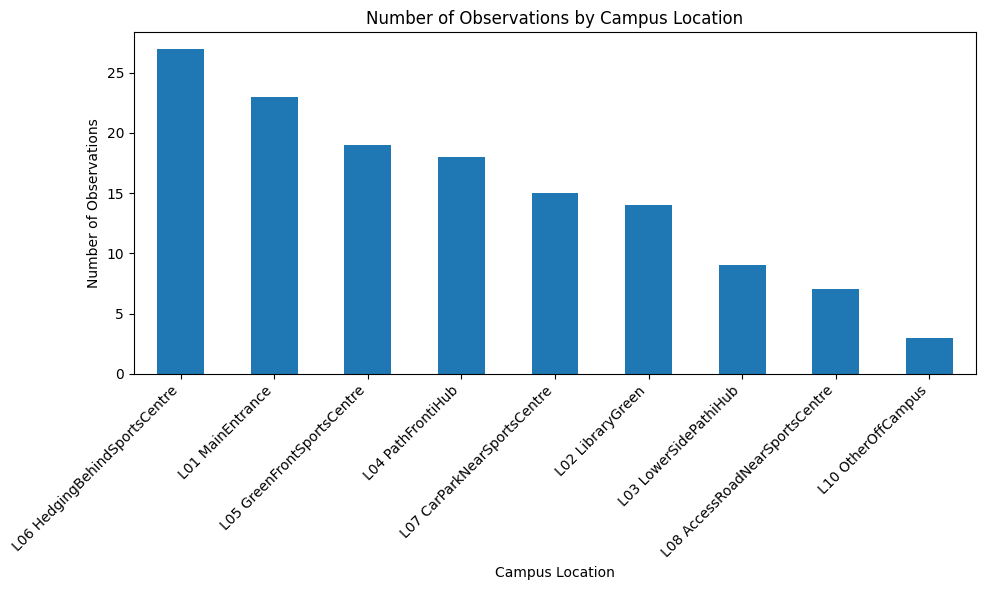

In [65]:

import matplotlib.pyplot as plt

#Count observations at each campus location
location_counts = df_clean['location'].value_counts()

#Create a bar chart
plt.figure(figsize=(10, 6))
location_counts.plot(kind='bar')

plt.title('Number of Observations by Campus Location')
plt.xlabel('Campus Location')
plt.ylabel('Number of Observations')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


#**Interpretation - Number of Observations by Campus Location**

I chose to use a bar chart because this is how I was imagining the data in my head. I thought it would be the easiest way to visually compare the number of observations collected at each campus location and clearly see the differences between them.

The bar chart shows that L06 HedgingBehindSportsCentre had the highest number of observations (27), followed by L01 MainEntrance (23). L10 OtherOffCampus had the lowest number of observations (3).

Looking at the graph, I noticed that the observations were not evenly distributed across the different locations. Some places had many more observations than others.

I think this is important because locations with more observations could have a greater influence on the overall results, while locations with fewer observations might be harder to compare reliably.

Creating this graph helped me understand how the observations were distributed across campus. It also gave me a clearer picture of the dataset before moving on to investigate how environmental factors, such as sound levels and natural features, might be related to people's stress and wellbeing.

#**Exploring Sound Levels and Stress**

##Compare sound levels with stress ratings

stress_rating,Mostly calm,Neutral,Stressful,Very calm,Very stressful
sound level,,,,,
Loud,41.2,41.2,11.8,5.9,0.0
Moderate,45.0,30.0,5.0,18.3,1.7
Quiet,43.1,22.4,3.4,31.0,0.0


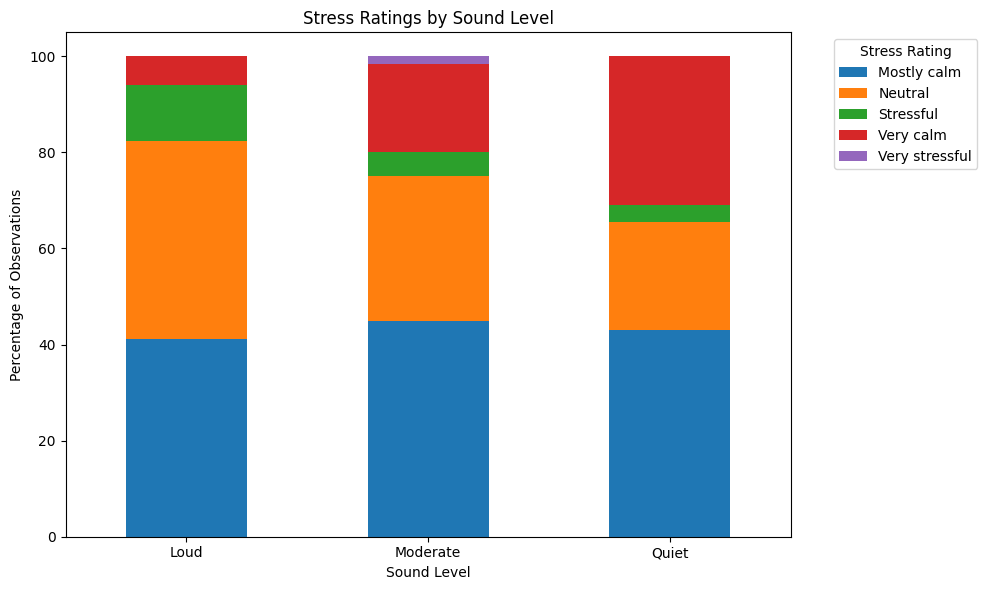

In [66]:
import pandas as pd
import matplotlib.pyplot as plt

sound_stress = pd.crosstab(
    df_clean['sound level'],
    df_clean['stress_rating'],
    normalize='index'
) * 100

display(sound_stress.round(1))

sound_stress.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Stress Ratings by Sound Level')
plt.xlabel('Sound Level')
plt.ylabel('Percentage of Observations')
plt.xticks(rotation=0)
plt.legend(title='Stress Rating', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

#**Interpretation - Stress Rating by Sound Level**

I chose to use a stacked bar chart because I wanted to compare the different stress ratings across loud, moderate and quiet environments. I thought this would be a good way to visualise the results because I could see the percentages of each stress category within the different sound levels.

Looking at the graph, I noticed that quiet environments had the highest percentage of people reporting feeling very calm (31%), compared with moderate environments (18.3%) and loud environments (5.9%).

I also noticed that the percentage of stressful ratings was higher in loud environments (11.8%) than in quiet environments (3.4%).

I found this interesting because it suggests that quieter environments may be associated with feeling calmer, while louder environments may be associated with more stress.

However, I understand that this graph does not prove that noise directly causes stress, because other environmental factors could also influence how people feel.

This graph helped me begin investigating the relationship between environmental characteristics and human experience, which is the main research question of my project.